# Eksplorasi Normalitas Return BBRI, BBCA, dan BRIS

**Saham:** BBRI.JK, BBCA.JK, BRIS.JK.  
**Tanggal return:** 10 November 2025 sampai 10 November 2026, termasuk kedua batas jika merupakan tanggal perdagangan.  
**Metode:** log return adjusted close, uji Lilliefors taraf 5%, histogram, dan Q–Q plot.

Jalankan dari atas ke bawah. Notebook ini hanya memeriksa normalitas; tidak menghitung bobot portofolio, VaR/CVaR, atau backtesting. Ketiga saham diuji pada interval perdagangan yang sama, sebelum dan sesudah penyaringan outlier satu kali

BSI (Bank Syariah Indonesia) menggunakan ticker **BRIS.JK**; ini berbeda dari BBSI.JK. Hasil percobaan sebelumnya dengan BMRI tetap tersimpan di `hasil/eksplorasi_normalitas/BBRI_BBCA_BMRI_2025-11-10_2026-11-10/`, beserta arsip notebook yang telah dijalankan.

## 1. Konfigurasi

| Variabel | Arti |
|---|---|
| `TICKERS` | Tiga saham yang diuji: BBRI, BBCA, dan BRIS. |
| `RETURN_START`, `RETURN_END` | Tanggal return 10 November 2025 sampai 10 November 2026. |
| `DOWNLOAD_START` | Awal unduhan, 14 hari kalender sebelum awal return agar tersedia harga sebelumnya. |
| `DOWNLOAD_END` | Sehari setelah akhir return, karena parameter `end` Yahoo bersifat eksklusif. |
| `ALPHA` | Taraf signifikansi uji Lilliefors: 0,05. |
| `OUTLIER_Z` | Ambang absolut z-score sebesar 3 untuk penyaringan sekali. |
| `REFRESH_DATA` | `False` memakai cache yang cocok; `True` mengunduh ulang. |

Data dan hasil berada dalam folder yang mencantumkan tiga ticker serta periode. Kalender harga tahun 2024 dari notebook utama tidak digunakan untuk periode baru ini.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from importlib.metadata import version
import hashlib
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from statsmodels.stats.diagnostic import lilliefors
from statsmodels.graphics.gofplots import qqplot
import yfinance as yf
from IPython.display import display

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
if not (ROOT / 'alur-penelitian.md').is_file():
    raise FileNotFoundError('Jalankan notebook dari root proyek TBP atau folder notebooks/.')

TICKERS = ['BBRI.JK', 'BBCA.JK', 'BRIS.JK']
RETURN_START = '2025-11-10'
RETURN_END = '2026-11-10'
DOWNLOAD_START = (pd.Timestamp(RETURN_START) - pd.Timedelta(days=14)).strftime('%Y-%m-%d')
DOWNLOAD_END = (pd.Timestamp(RETURN_END) + pd.Timedelta(days=1)).strftime('%Y-%m-%d')
ALPHA = 0.05
OUTLIER_Z = 3.0
REFRESH_DATA = False

study_id = '_'.join(ticker.replace('.JK', '') for ticker in TICKERS) + f'_{RETURN_START}_{RETURN_END}'
DATA_DIR = ROOT / 'data' / 'eksplorasi_normalitas' / study_id
RESULT_DIR = ROOT / 'hasil' / 'eksplorasi_normalitas' / study_id
DATA_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)
VERSIONS = {name: version(name) for name in ['numpy', 'pandas', 'scipy', 'statsmodels', 'matplotlib', 'yfinance']}
display(pd.Series({'saham': ', '.join(TICKERS), 'awal_return': RETURN_START,
                   'akhir_return': RETURN_END, 'awal_unduhan': DOWNLOAD_START,
                   'akhir_unduhan_eksklusif': DOWNLOAD_END,
                   'alpha': ALPHA, 'ambang_z': OUTLIER_Z}, name='konfigurasi').to_frame())

,konfigurasi
saham,"BBRI.JK, BBCA.JK, BRIS.JK"
awal_return,2025-11-10
akhir_return,2026-11-10
awal_unduhan,2025-10-27
akhir_unduhan_eksklusif,2026-11-11
alpha,0.05
ambang_z,3.0


## 2. Mengambil harga adjusted

Gunakan `Adj Close` dengan `auto_adjust=False`. Cache menyimpan spesifikasi permintaan, waktu unduh, versi alat, dan hash data. Ketiga ticker wajib tersedia; data parsial tidak dilanjutkan secara otomatis.

Satu harga terakhir sebelum 10 November 2025 akan dipakai sebagai pembanding untuk return hari pertama. Unduhan sampai batas eksklusif 11 November 2026 mencakup harga 10 November 2026.

In [2]:
request_spec = {
    'tickers': TICKERS, 'start': DOWNLOAD_START, 'end': DOWNLOAD_END,
    'interval': '1d', 'auto_adjust': False, 'back_adjust': False,
    'actions': True, 'repair': False, 'keepna': True,
    'group_by': 'column', 'multi_level_index': True, 'ignore_tz': True,
}
raw_path = DATA_DIR / 'yahoo_ohlcv.csv'
metadata_path = DATA_DIR / 'yahoo_metadata.json'
if raw_path.exists() and not REFRESH_DATA:
    source_metadata = json.loads(metadata_path.read_text(encoding='utf-8'))
    if source_metadata['request'] != request_spec:
        raise ValueError('Konfigurasi cache berbeda. Periksa konfigurasi lalu set REFRESH_DATA=True.')
    if hashlib.sha256(raw_path.read_bytes()).hexdigest() != source_metadata['sha256_csv']:
        raise ValueError('Hash cache tidak cocok; periksa sumber sebelum melanjutkan.')
    raw = pd.read_csv(raw_path, header=[0, 1], index_col=0, parse_dates=True, float_precision='round_trip')
    print('Memakai cache:', source_metadata['downloaded_at_utc'])
else:
    raw = yf.download(**request_spec, threads=False, progress=False, timeout=30)
    if raw is None or raw.empty:
        raise RuntimeError('Yahoo Finance tidak mengembalikan data untuk periode yang diminta.')
    required = {('Adj Close', ticker) for ticker in TICKERS}
    if not isinstance(raw.columns, pd.MultiIndex) or not required.issubset(set(raw.columns)):
        raise ValueError('Adj Close ketiga saham tidak tersedia dalam format yang diharapkan.')
    raw.to_csv(raw_path, float_format='%.17g')
    source_metadata = {
        'source': 'Yahoo Finance via yfinance', 'request': request_spec,
        'downloaded_at_utc': datetime.now(timezone.utc).isoformat(), 'versions': VERSIONS,
        'sha256_csv': hashlib.sha256(raw_path.read_bytes()).hexdigest(),
    }
    metadata_path.write_text(json.dumps(source_metadata, indent=2), encoding='utf-8')

downloaded_prices = raw['Adj Close'].reindex(columns=TICKERS).astype(float)
downloaded_prices.index = pd.DatetimeIndex(downloaded_prices.index).tz_localize(None).normalize()
if downloaded_prices.index.has_duplicates:
    raise ValueError('Tanggal harga duplikat; periksa sumber.')
downloaded_prices = downloaded_prices.sort_index()
if downloaded_prices.isna().all().any():
    raise ValueError('Ada saham tanpa harga valid; unduhan parsial tidak dipakai.')
if ((downloaded_prices <= 0) | np.isinf(downloaded_prices)).any().any():
    raise ValueError('Ada harga nonpositif/tidak hingga yang perlu diperiksa.')
display(downloaded_prices.head())

Memakai cache: 2026-11-15T01:26:14.500446+00:00


Ticker,BBRI.JK,BBCA.JK,BRIS.JK
Date,,,
2025-10-27,3494.083008,7891.346191,2553.384521
2025-10-28,3485.030762,7820.465820,2514.101807
2025-10-29,3521.239014,8127.613281,2553.384521
2025-10-30,3539.343018,8056.733398,2523.922363
2025-10-31,3602.707275,8056.733398,2504.281006


## 3. Menyelaraskan tanggal dan menghitung log return

$$r_{i,t}=\ln(P_{i,t}/P_{i,t-1}).$$

Ketiga saham memakai gabungan tanggal unduhan periode baru. Harga tidak diisi maju. Jika ada harga hilang untuk salah satu saham, proses berhenti untuk pemeriksaan, sehingga interval tetap sama dan penghapusan tanggal tidak menyamarkan return beberapa hari menjadi sehari.

Pemeriksaan ini memakai tanggal penyedia dan belum merupakan verifikasi independen kalender BEI. Untuk rentang spesifik ini, kedua tanggal batas diminta tersedia; jika tidak, periksa kelengkapan sumber atau kalender sebelum mengubah rentang. Return mengikuti definisi adjusted close, termasuk penyesuaian dividen bila tercakup dalam seri.

In [3]:
before = downloaded_prices.loc[downloaded_prices.index < pd.Timestamp(RETURN_START)]
if before.empty or before.iloc[-1].isna().any():
    raise ValueError('Harga lengkap pada tanggal perdagangan sebelum awal periode tidak tersedia.')
prices = downloaded_prices.loc[before.index[-1]:RETURN_END].copy()
prices.index.name = 'date'
prices.to_csv(DATA_DIR / 'harga_adjusted.csv', float_format='%.17g')
missing = prices.isna()
missing.to_csv(RESULT_DIR / 'harga_hilang.csv', index_label='date')
if missing.any().any():
    raise ValueError('Ada harga hilang. Periksa harga_hilang.csv; tidak dilakukan forward fill.')
for boundary in [RETURN_START, RETURN_END]:
    if pd.Timestamp(boundary) not in prices.index:
        raise ValueError(f'Harga tanggal batas {boundary} tidak tersedia. Periksa cakupan data/kalender sebelum melanjutkan.')

returns = np.log(prices / prices.shift(1)).loc[RETURN_START:RETURN_END]
if returns.isna().any().any() or not np.isfinite(returns.to_numpy()).all():
    raise ValueError('Return belum lengkap atau mengandung nilai tidak valid.')
if len(returns) < 4 or (returns.std(ddof=1) <= 0).any():
    raise ValueError('Return tidak cukup atau ada saham tanpa variasi untuk uji normalitas.')
returns.to_csv(DATA_DIR / 'return_mentah.csv', index_label='date', float_format='%.17g')
quality = pd.DataFrame({
    'n_harga': prices.notna().sum(), 'n_return': returns.count(),
    'return_pertama': str(returns.index.min().date()),
    'return_terakhir': str(returns.index.max().date()),
    'n_return_nol': returns.eq(0).sum(), 'proporsi_return_nol': returns.eq(0).mean(),
})
quality.to_csv(RESULT_DIR / 'kualitas_data.csv', index_label='ticker')
display(quality)

,n_harga,n_return,return_pertama,return_terakhir,n_return_nol,proporsi_return_nol
Ticker,,,,,,
BBRI.JK,241,240,2025-11-10,2026-11-10,12,0.050000
BBCA.JK,241,240,2025-11-10,2026-11-10,17,0.070833
BRIS.JK,241,240,2025-11-10,2026-11-10,26,0.108333


## 4. Penyaringan outlier satu kali pada tanggal bersama

Hitung z-score tiap saham dari sampel mentah. Sebuah tanggal ditandai jika **salah satu saham** memiliki $|z|>3$, lalu seluruh baris tanggal tersebut dikeluarkan dari sampel tersaring untuk ketiga saham. Ini mengikuti aturan portofolio utama dan menjaga jumlah/tanggal observasi sama antar saham pada setiap perlakuan.

Penyaringan dilakukan sekali. Tidak ada pengulangan penghapusan data untuk mengejar p-value tertentu. Hasil tanpa filter tetap disimpan.

In [4]:
z_scores = (returns - returns.mean()) / returns.std(ddof=1)
flagged_by_asset = z_scores.abs().gt(OUTLIER_Z)
marked = flagged_by_asset.any(axis=1)
samples = {'tanpa_filter': returns, 'tersaring': returns.loc[~marked]}
if len(samples['tersaring']) < 4 or (samples['tersaring'].std(ddof=1) <= 0).any():
    raise ValueError('Sampel tersaring tidak cukup atau ada saham tanpa variasi untuk Lilliefors.')
outliers = returns.loc[marked].add_prefix('return_').join(z_scores.loc[marked].add_prefix('z_'))
outliers.to_csv(RESULT_DIR / 'outlier.csv', index_label='date')
flagged_by_asset.to_csv(RESULT_DIR / 'penanda_outlier_per_saham.csv', index_label='date')
samples['tersaring'].to_csv(DATA_DIR / 'return_tersaring.csv', index_label='date', float_format='%.17g')
print('Tanggal ditandai:', int(marked.sum()), '| return sebelum/sesudah:', len(returns), '/', len(samples['tersaring']))
display(flagged_by_asset.sum().rename('n_outlier_individual').to_frame())
display(outliers)

Tanggal ditandai: 9 | return sebelum/sesudah: 240 / 231


,n_outlier_individual
Ticker,
BBRI.JK,3
BBCA.JK,4
BRIS.JK,6


Ticker,return_BBRI.JK,return_BBCA.JK,return_BRIS.JK,z_BBRI.JK,z_BBCA.JK,z_BRIS.JK
date,,,,,,
2026-05-07,0.046376,0.045182,0.092049,2.068896,1.886682,3.372764
2026-05-25,0.038590,0.033336,0.086307,1.729025,1.411162,3.169537
2026-06-08,-0.056300,-0.045348,-0.088816,-2.412977,-1.747400,-3.028292
2026-06-09,0.074384,0.060018,0.130431,3.291441,2.482225,4.731136
2026-06-10,0.031749,0.092659,0.005420,1.430399,3.792502,0.306842
2026-07-17,0.037740,0.039375,0.093218,1.691937,1.653574,3.414135
2026-10-16,-0.160623,-0.160343,-0.160004,-6.966740,-6.363554,-5.547755
2026-10-20,0.093878,0.075885,0.033738,4.142356,3.119151,1.309057
2026-10-28,0.006873,0.073743,0.018868,0.344556,3.033197,0.782799


## 5. Uji Lilliefors

- $H_0$: return saham berasal dari distribusi normal dengan parameter yang diestimasi.
- $H_1$: return tidak mengikuti distribusi normal tersebut.
- Jika p-value $<0{,}05$, **tolak $H_0$**; selain itu **tidak menolak $H_0$**, bukan membuktikan normalitas.

Uji dilakukan per saham pada kedua perlakuan, menghasilkan enam baris. P-value pada batas tabel ditulis sebagai batas. Hasil setelah penyaringan bersifat eksploratif karena distribusi sampel telah dipengaruhi seleksi. Normalitas masing-masing saham belum membuktikan normalitas gabungannya.

In [5]:
rows = []
for treatment, frame in samples.items():
    for ticker in TICKERS:
        sample = frame[ticker]
        statistic, p_value = lilliefors(sample, dist='norm', pvalmethod='table')
        p_label = (f'<= {p_value:.3f}' if p_value <= 0.001
                   else f'>= {p_value:.3f}' if p_value >= 0.990 else f'{p_value:.6f}')
        rows.append({
            'ticker': ticker, 'perlakuan': treatment, 'n': len(sample),
            'mean': float(sample.mean()), 'sd': float(sample.std(ddof=1)),
            'skewness': float(sample.skew()), 'excess_kurtosis': float(sample.kurt()),
            'D': float(statistic), 'p_value_table': float(p_value), 'p_value_tampil': p_label,
            'alpha': ALPHA, 'outlier_z': OUTLIER_Z,
            'keputusan': 'Tolak H0' if p_value < ALPHA else 'Tidak menolak H0',
            'sifat': 'eksploratif setelah seleksi' if treatment == 'tersaring' else 'diagnosis return mentah',
        })
normality_table = pd.DataFrame(rows)
normality_table.to_csv(RESULT_DIR / 'uji_normalitas.csv', index=False)
display(normality_table[['ticker', 'perlakuan', 'n', 'D', 'p_value_tampil', 'keputusan', 'sifat']])
display(normality_table[['ticker', 'perlakuan', 'mean', 'sd', 'skewness', 'excess_kurtosis']])

,ticker,perlakuan,n,D,p_value_tampil,keputusan,sifat
0,BBRI.JK,tanpa_filter,240,0.098419,<= 0.001,Tolak H0,diagnosis return mentah
1,BBCA.JK,tanpa_filter,240,0.106451,<= 0.001,Tolak H0,diagnosis return mentah
2,BRIS.JK,tanpa_filter,240,0.123553,<= 0.001,Tolak H0,diagnosis return mentah
3,BBRI.JK,tersaring,231,0.066778,0.020224,Tolak H0,eksploratif setelah seleksi
4,BBCA.JK,tersaring,231,0.070784,0.009658,Tolak H0,eksploratif setelah seleksi
5,BRIS.JK,tersaring,231,0.098393,<= 0.001,Tolak H0,eksploratif setelah seleksi


,ticker,perlakuan,mean,sd,skewness,excess_kurtosis
0,BBRI.JK,tanpa_filter,-0.001021,0.022909,-1.048970,10.625468
1,BBCA.JK,tanpa_filter,-0.001818,0.024911,-0.849863,7.871200
2,BRIS.JK,tanpa_filter,-0.003250,0.028255,0.175581,6.983640
3,BBRI.JK,tersaring,-0.001548,0.018142,-0.132818,0.838581
4,BBCA.JK,tersaring,-0.002817,0.019937,-0.537234,1.678700
5,BRIS.JK,tersaring,-0.004291,0.022112,0.339096,2.174636


## 6. Histogram dan Q–Q plot

Untuk setiap perlakuan, tiga baris gambar mewakili BBRI, BBCA, dan BRIS. Histogram dibandingkan dengan densitas normal yang mean/SD-nya diestimasi dari sampel terkait. Pada Q–Q plot, perhatikan penyimpangan titik dari garis, terutama pada ekor.

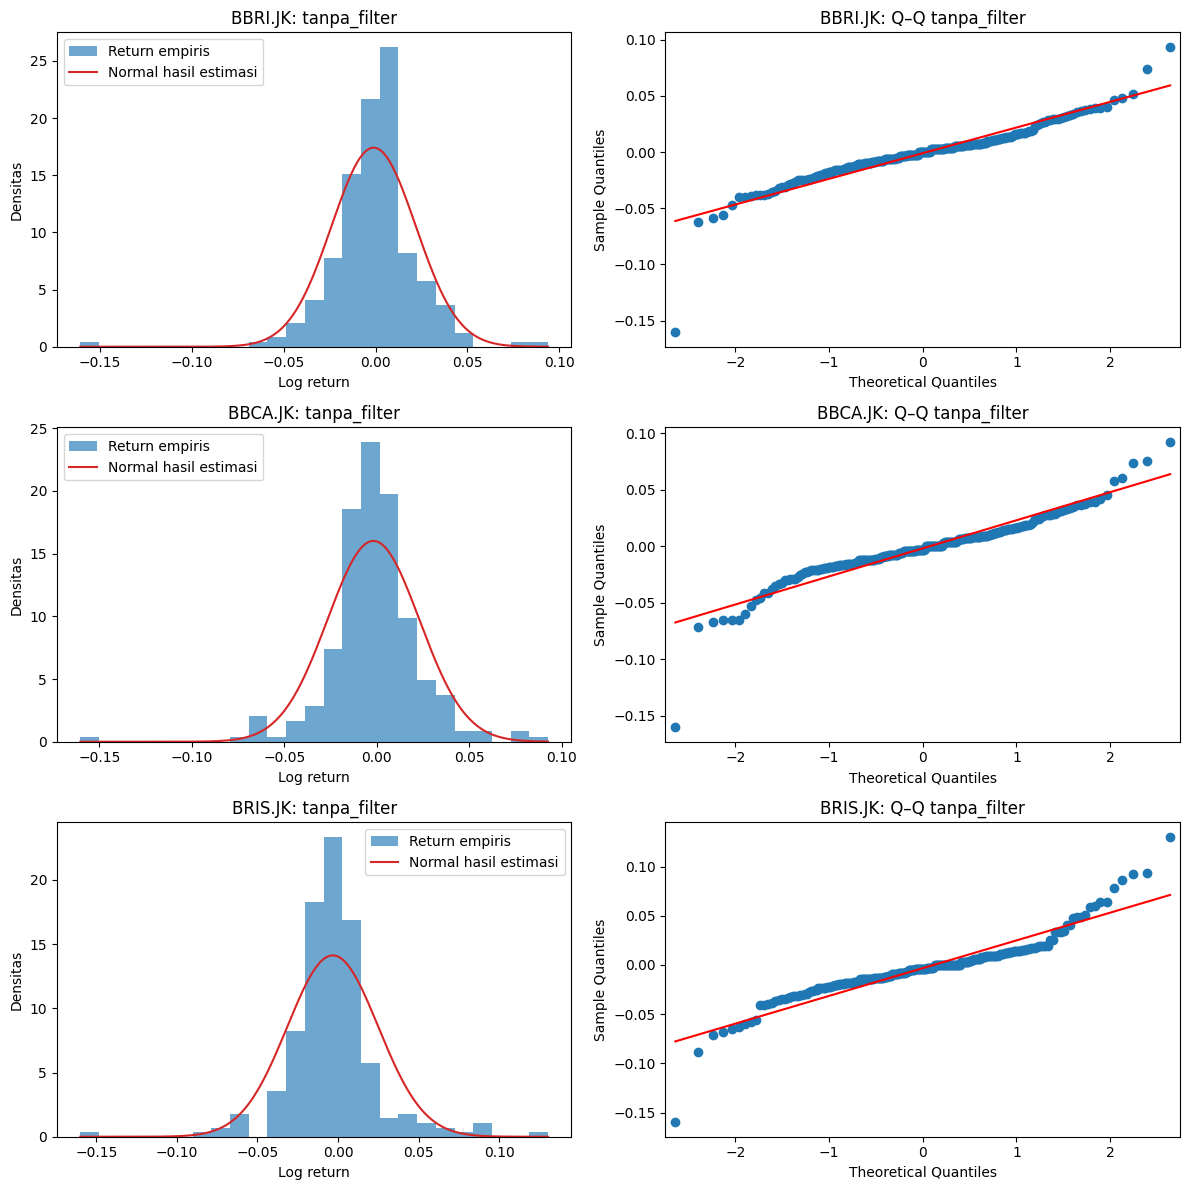

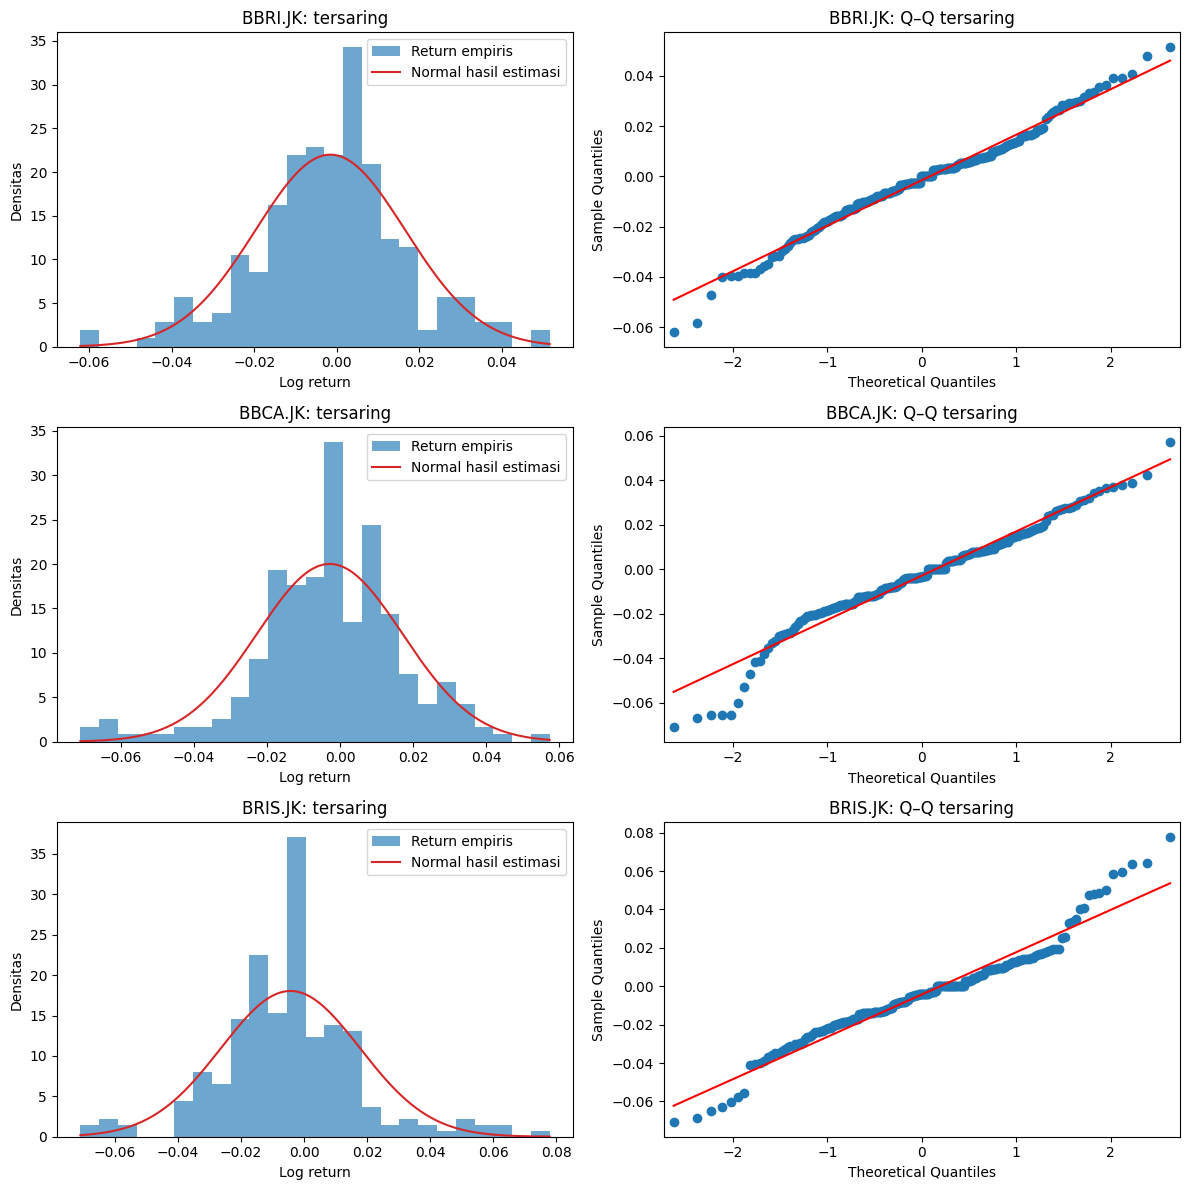

In [6]:
for treatment, frame in samples.items():
    fig, axes = plt.subplots(len(TICKERS), 2, figsize=(12, 4 * len(TICKERS)), squeeze=False)
    for row, ticker in enumerate(TICKERS):
        sample = frame[ticker]
        ax = axes[row, 0]
        ax.hist(sample, bins=25, density=True, alpha=0.65, label='Return empiris')
        x = np.linspace(sample.min(), sample.max(), 300)
        ax.plot(x, norm.pdf(x, loc=sample.mean(), scale=sample.std(ddof=1)),
                color='tab:red', label='Normal hasil estimasi')
        ax.set(title=f'{ticker}: {treatment}', xlabel='Log return', ylabel='Densitas')
        ax.legend()
        qqplot(sample, line='s', ax=axes[row, 1])
        axes[row, 1].set_title(f'{ticker}: Q–Q {treatment}')
    fig.tight_layout()
    fig.savefig(RESULT_DIR / f'histogram_qq_{treatment}.png', dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)

## 7. Ringkasan periode eksplorasi

Ringkasan membandingkan kedua perlakuan untuk setiap saham pada periode 10 November 2025–10 November 2026. Simpan seluruh hasil, termasuk penolakan normalitas. Pemeriksaan periode baru ini tidak otomatis mengubah metodologi atau data tahun 2024 pada notebook utama.

In [7]:
comparison = normality_table.pivot(index='ticker', columns='perlakuan',
                                  values=['n', 'p_value_tampil', 'keputusan']).reindex(TICKERS)
comparison.columns = [f'{metric}_{treatment}' for metric, treatment in comparison.columns]
comparison.to_csv(RESULT_DIR / 'ringkasan_per_saham.csv')
display(comparison)
for _, row in normality_table.iterrows():
    statement = ('normalitas ditolak' if row['keputusan'] == 'Tolak H0'
                 else 'normalitas tidak ditolak; belum merupakan bukti pasti normal')
    print(f"{row['ticker']} | {row['perlakuan']} | n={row['n']} | "
          f"p {row['p_value_tampil']} | {statement} pada taraf {ALPHA:.0%}.")

metadata = {
    'tickers': TICKERS, 'return_start': RETURN_START, 'return_end': RETURN_END,
    'actual_return_start': str(returns.index.min().date()),
    'actual_return_end': str(returns.index.max().date()),
    'alpha': ALPHA, 'outlier_z': OUTLIER_Z, 'filter_passes': 1,
    'outlier_rule': 'remove entire date if any asset abs(z) exceeds threshold',
    'date_alignment': 'common price intervals from new-period Yahoo union; no 2024 reference',
    'n_returns': len(returns), 'n_outlier_dates': int(marked.sum()),
    'n_filtered_returns': len(samples['tersaring']), 'versions': VERSIONS,
    'source_metadata': source_metadata, 'purpose': 'exploratory normality for alternative period only',
    'recorded_at_utc': datetime.now(timezone.utc).isoformat(),
}
(RESULT_DIR / 'konfigurasi.json').write_text(json.dumps(metadata, indent=2), encoding='utf-8')
print('Periode return aktual:', returns.index.min().date(), 'sampai', returns.index.max().date())
print('Hasil eksplorasi:', RESULT_DIR)

,n_tanpa_filter,n_tersaring,p_value_tampil_tanpa_filter,p_value_tampil_tersaring,keputusan_tanpa_filter,keputusan_tersaring
ticker,,,,,,
BBRI.JK,240,231,<= 0.001,0.020224,Tolak H0,Tolak H0
BBCA.JK,240,231,<= 0.001,0.009658,Tolak H0,Tolak H0
BRIS.JK,240,231,<= 0.001,<= 0.001,Tolak H0,Tolak H0


BBRI.JK | tanpa_filter | n=240 | p <= 0.001 | normalitas ditolak pada taraf 5%.
BBCA.JK | tanpa_filter | n=240 | p <= 0.001 | normalitas ditolak pada taraf 5%.
BRIS.JK | tanpa_filter | n=240 | p <= 0.001 | normalitas ditolak pada taraf 5%.
BBRI.JK | tersaring | n=231 | p 0.020224 | normalitas ditolak pada taraf 5%.
BBCA.JK | tersaring | n=231 | p 0.009658 | normalitas ditolak pada taraf 5%.
BRIS.JK | tersaring | n=231 | p <= 0.001 | normalitas ditolak pada taraf 5%.
Periode return aktual: 2025-11-10 sampai 2026-11-10
Hasil eksplorasi: f:\Semester 7\Manrisk\TBP\hasil\eksplorasi_normalitas\BBRI_BBCA_BRIS_2025-11-10_2026-11-10


Rujukan: [Lilliefors statsmodels](https://www.statsmodels.org/stable/generated/statsmodels.stats.diagnostic.lilliefors.html), [parameter yfinance.download](https://ranaroussi.github.io/yfinance/reference/api/yfinance.download.html), dan [alur penelitian utama](../alur-penelitian.md).